# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Laughney 2020's LUAD malignant manifold is **non-branching**: the developmental signatures
collapse onto a **single dominant axis** — posterior-somitogenesis-high (pSom) at one pole opposed to
neural-crest (Crest) at a terminal end — rather than a hub radiating to discrete subtypes with
cross-repression. A PPT *tree* over this cloud throws spurious forks (200 nodes spidering
a continuous 2.9k-cell blob — the executed cell below reports the branch-node count), but the geometry that matters is the signature
geography: one gastrulation/somitogenesis → neural-crest gradient (Crest anti-correlated with
both), Crest a single terminal tip. The correct topology is therefore a **principal curve**
(ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a re-embedding
(re-embedding an anisotropic compartment fabricates folds; the Kürten §4 / Chen failure mode).

**Scope decision (derived, not inherited).** Laughney's malignant cells carry no cell-cycle
annotation and a flat data-derived proliferation score, so there is **no cycling compartment** to
scope out (contrast Qian/Kürten). The whole malignant manifold is one developmental cloud and is
kept intact. The curve is rooted at the posterior-somitogenesis (pSom)-high tip; pseudotime flows to
the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared
**union** control pool and graph-smoothed to read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 2734 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.14
Gast: 74/81 genes present
pSom: 87/98 genes present
Crest: 100/104 genes present
raw module means (honest readout): {'Gast': -0.0319, 'pSom': 0.0634, 'Crest': -0.0292}


### Signature geography — one developmental axis, no cross-repression hub
The dominant developmental contrast is **neural-crest vs the gastrulation/somitogenesis body**:
Crest is strongly spatially anti-correlated with both Gast and pSom, while Gast and pSom are roughly
**independent** (weak spatial correlation) rather than competitively opposing each other. That is
the non-branching signature (a single Crest-inverse axis), *not* Puram's Gast↔pSom cross-repression
hub. There is no cell-cycle annotation and a
flat proliferation score, so no lobe scoping is warranted; the whole manifold is the trajectory
object.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nproliferation / cell-cycle confound check:')
print('  cell_cycle_phase annotated cells:', int(adata.obs['cell_cycle_phase'].astype(str).ne('nan').sum()))
print('  proliferation score per low-res lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict(),
      '(flat -> not a proliferative axis)')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.11
  Crest_sm vs Gast_sm: r = -0.72
  Crest_sm vs pSom_sm: r = -0.45

proliferation / cell-cycle confound check:
  cell_cycle_phase annotated cells: 0
  proliferation score per low-res lobe: {'0': 0.003, '1': -0.029} (flat -> not a proliferative axis)


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself (the Kürten/Chen fold failure mode). `epg_mu=100` is strong
bending regularisation, keeping the arc smooth. Fold-freeness and the 2-tip / 0-fork topology are
stable across Nodes = 15/20/30. A PPT *tree* on the same cloud is shown to throw spurious
forks — confirming the curve, not the tree, is the correct topology.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
# PPT tree on the same cloud -> spurious forks (why not a tree)
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print(f'PPT tree(200 nodes): {int(((Bt>0).sum(0)==1).sum())} tips, '
      f'{int(((Bt>0).sum(0)>=3).sum())} forks (spurious -> use curve, not tree)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.98
curve N=30: 2 tips, 0 forks | self-approach 2.93
PPT tree(200 nodes): 6 tips, 4 forks (spurious -> use curve, not tree)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


### Derive the root (data-driven)
The origin is the **posterior-somitogenesis (pSom) pole**: pSom is by far the strongest, most
origin-concentrated developmental module here (highest at low pseudotime, declining along the axis),
so the root is the curve tip where **pSom is highest and Crest lowest**. Gast is weak on this
manifold (its raw mean is the lowest of the three and it is essentially flat / mildly
terminus-trending — see below), so it is **not** used to place the root; scoring the tips by
`pSom−Crest` vs `Gast+pSom−Crest` selects the same tip, confirming pSom (not Gast) drives the origin.
Pseudotime then flows to the neural-crest terminus — the developmentally-ordered root (Crest is
*late*; the Kürten root lesson), read from the signatures, not from a subtype name or a
proliferation state.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} '
          f'| pSom-Crest={info[tp][1]-info[tp][2]:+.4f}')
# origin = pSom-high / Crest-low pole (pSom is the dominant, origin-concentrated module)
root = int(max(tps, key=lambda tp: info[tp][1]-info[tp][2]))
root_alt = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print(f'derived root = tip {root} (pSom-high, Crest-low origin); '
      f'Gast+pSom-Crest scoring gives tip {root_alt} -> {"same tip (pSom drives it, not Gast)" if root==root_alt else "DIFFERS"}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0341 pSom=+0.0502 Crest=-0.0199 | pSom-Crest=+0.0701
tip 2: Gast=-0.0398 pSom=+0.0712 Crest=-0.0260 | pSom-Crest=+0.0973
derived root = tip 2 (pSom-high, Crest-low origin); Gast+pSom-Crest scoring gives tip 2 -> same tip (pSom drives it, not Gast)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.256 p=5.1e-42
  pSom_sm: rho=-0.871 p=0.0e+00
  Crest_sm: rho=+0.257 p=1.2e-42
Neural-crest-high decile mean pseudotime = 0.68
Somitogenesis-high decile mean pseudotime = 0.09
Gastrulation-high decile mean pseudotime = 0.48


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal —
was derived **once in 01** (rotation angle from the manifold's axis of maximal variance; sign set
from the developmental-module geography, posterior-somitogenesis (pSom)-high origin on the left) and
stored as `X_umap_lin`. Every UMAP deliverable across 01–04 re-uses these exact coordinates, so
orientation is consistent by construction (binding). Here we **verify** that layout now that
pseudotime exists: the correlation of the stored `X_umap_lin` x-axis with pseudotime must be
strongly positive (low pseudotime = developmental origin on the left).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 0.6deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis.

saved manifold.h5ad + manifold.pdf


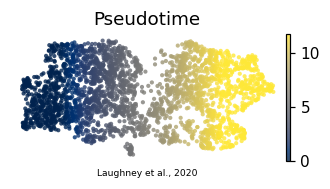

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Laughney et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')